# M115 Lab 1: Phishing URL Detection — EDA, Parameterized Logistic Regression & SHAP Explainability

---

## 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027

---

## 🧭 Lab Overview & Solution Key

This notebook contains the assignment of **Lab 1** on the **[PhiUSIIL Phishing URL Dataset](https://www.kaggle.com/datasets/kaggleprollc/phishing-url-websites-dataset-phiusiil/data)** (*235,795 URLs and 56 lexical, network, and HTML features*, Prasad & Chandra, *Computers & Security*, 2024).

### 📋 Table of Contents
* **1 - Importing Packages & Loading Data**
* **2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)**
  * 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)
  * 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)
  * 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)
  * *Part 1 Reflection Questions*
* **3 - Part 2: Zero-Data Leakage Preprocessing & Standardization**
  * 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)
  * *Part 2 Reflection Questions*
* **4 - Part 3: Parameterized Logistic Regression & Interpretability**
  * 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)
  * 4.2 L1 Regularization Path & Feature Selection (Exercise 6)
  * 4.3 Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)
  * *Part 3 Reflection Questions*
* **5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis**
  * 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)
  * 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)
  * 5.3 Operational Decision Threshold Tuning ($\tau \in \{0.20, 0.50, 0.85\}$) (Exercise 10)
  * *Part 4 Reflection Questions*
* **6 - Conclusion & SOC Engineering Synthesis**

---
## 1 - Importing Packages & Loading Data

Run the cell below to import the required libraries and configure reproducibility (`SEED = 42`):

---
## 2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)

### 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)

First, we load `PhiUSIIL_Phishing_URL_Dataset.csv` and inspect its shape, data types, missing values, duplicate rows, and summary statistics across key numerical features (`URLLength`, `LineOfCode`, `CharContinuationRate`, `NoOfSelfRef`).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score
)
import shap

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 4.5)
SEED = 42
np.random.seed(SEED)

df = pd.read_csv(r"C:\Users\C1300\OneDrive\Desktop\projet ai\PhiUSIIL_Phishing_URL_Dataset\PhiUSIIL_Phishing_URL_Dataset.csv")
pd.set_option("display.max_columns", None)
print(df.shape)
df.head()

(235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [2]:
%pip install shap

Defaulting to user installation because normal site-packages is not writeable
  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached shap-0.54.1-cp312-abi3-win_amd64.whl (751 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ----------------

> **⚠️ Critical Cyber Label Warning in PhiUSIIL:**  
> In the raw CSV file, **`label = 1` denotes Legitimate (Benign)** and **`label = 0` denotes Phishing (Malicious)**.  
> In a SOC, the positive class (`1`) **must always represent the attack** (`Phishing = 1`, `Benign = 0`) so that True Positives (TP), Precision, and Recall measure our threat detection capability.

### Exercise 1

In [4]:
# Load dataset and inspect data quality
df = pd.read_csv(r"C:\Users\C1300\OneDrive\Desktop\projet ai\PhiUSIIL_Phishing_URL_Dataset\PhiUSIIL_Phishing_URL_Dataset.csv")
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("\nDataset Info:")
df.info()

display(df[['FILENAME', 'URL', 'URLLength', 'LineOfCode', 'IsHTTPS', 'HasPasswordField', 'NoOfSelfRef', 'label']].head(5))
display(df[['URLLength', 'LineOfCode', 'CharContinuationRate', 'NoOfSelfRef']].describe().round(2))

Dataset Shape: (235795, 56)
Total Missing Values: 0
Duplicate Rows: 0

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12

,FILENAME,URL,URLLength,LineOfCode,IsHTTPS,HasPasswordField,NoOfSelfRef,label
0,521848.txt,https://www.southbankmosaics.com,31,558,1,0,119,1
1,31372.txt,https://www.uni-mainz.de,23,618,1,0,39,1
2,597387.txt,https://www.voicefmradio.co.uk,29,467,1,0,42,1
3,554095.txt,https://www.sfnmjournal.com,26,6356,1,0,22,1
4,151578.txt,https://www.rewildingargentina.org,33,6089,1,0,72,1


,URLLength,LineOfCode,CharContinuationRate,NoOfSelfRef
count,235795.00,235795.00,235795.00,235795.00
mean,34.57,1141.90,0.85,65.07
std,41.31,3419.95,0.22,176.69
min,13.00,2.00,0.00,0.00
25%,23.00,18.00,0.68,0.00
50%,27.00,429.00,1.00,12.00
75%,34.00,1277.00,1.00,88.00
max,6097.00,442666.00,1.00,27397.00


In [5]:
# EXERCISE 1: Data Quality & SOC Target Alignment (1 = Phishing, 0 = Benign)

### START CODE HERE ### (≈ 2 lines of code)
df['IsPhishing'] = 1 - df['label']
phishing_ratio = df['IsPhishing'].mean()
### END CODE HERE ###

print(f"Phishing URLs (1): {(df['IsPhishing'] == 1).sum():,}")
print(f"Legitimate URLs (0): {(df['IsPhishing'] == 0).sum():,}")
print(f"Phishing Proportion: {phishing_ratio * 100:.2f}%")
print("\nNormalized Class Proportions:")
print(df['IsPhishing'].value_counts(normalize=True).round(4))

Phishing URLs (1): 100,945
Legitimate URLs (0): 134,850
Phishing Proportion: 42.81%

Normalized Class Proportions:
IsPhishing
0    0.5719
1    0.4281
Name: proportion, dtype: float64


---
### 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)

We compare legitimate (`0`) and phishing (`1`) URLs across class balance, continuous lexical/HTML features (`URLLength`, `CharContinuationRate`, `NoOfSelfRef`), and binary security indicators (`IsHTTPS`, `HasPasswordField`, `HasCopyrightInfo`, `HasSocialNet`).

### Exercise 2

Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):


,IsHTTPS,HasPasswordField,HasCopyrightInfo,HasSocialNet
IsPhishing,,,,
0,100.00,13.85,80.82,79.46
1,49.22,5.39,5.73,0.51


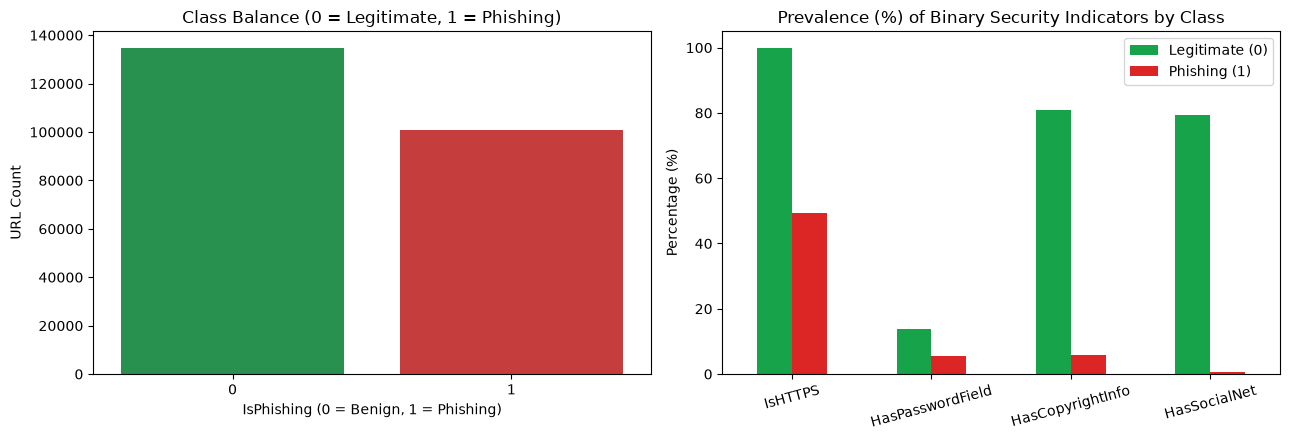

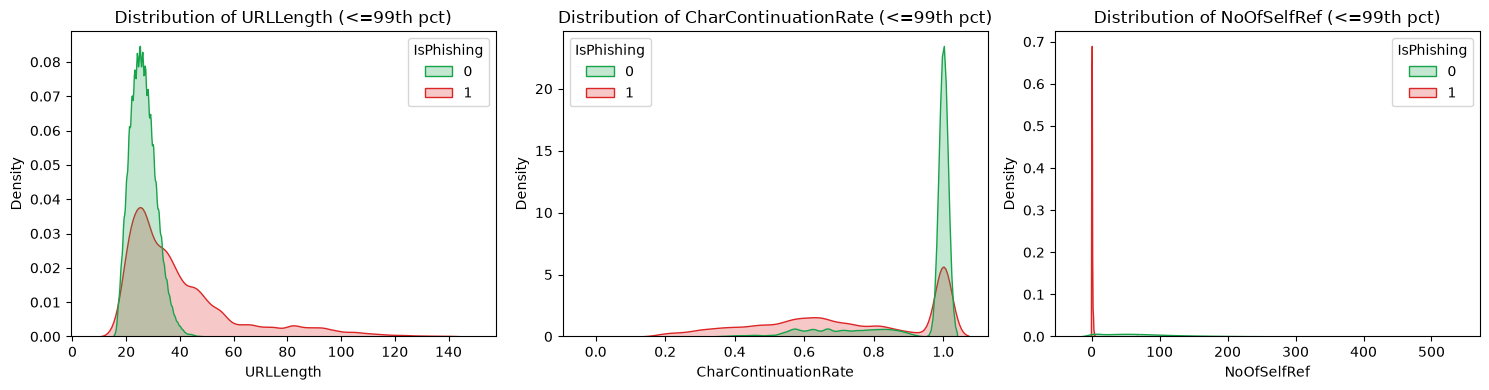

In [6]:
# EXERCISE 2: Visualizing Distributions and Binary Security Indicators
binary_cols = ['IsHTTPS', 'HasPasswordField', 'HasCopyrightInfo', 'HasSocialNet']
num_cols = ['URLLength', 'CharContinuationRate', 'NoOfSelfRef']

### START CODE HERE ### (≈ 1 line of code)
binary_stats = df.groupby('IsPhishing')[binary_cols].mean() * 100
### END CODE HERE ###

print("Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):")
display(binary_stats.round(2))

# 1. Class Balance & Binary Indicators Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x='IsPhishing', hue='IsPhishing', ax=axes[0], palette=['#16a34a', '#dc2626'], legend=False)
axes[0].set_title("Class Balance (0 = Legitimate, 1 = Phishing)")
axes[0].set_xlabel("IsPhishing (0 = Benign, 1 = Phishing)")
axes[0].set_ylabel("URL Count")

binary_stats.T.plot(kind='bar', ax=axes[1], color=['#16a34a', '#dc2626'])
axes[1].set_title("Prevalence (%) of Binary Security Indicators by Class")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xticklabels(binary_cols, rotation=15)
axes[1].legend(["Legitimate (0)", "Phishing (1)"])
plt.tight_layout()
plt.show()

# 2. Numerical Distributions (KDE Plots clipped at 99th percentile for readability)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(num_cols):
    upper_clip = df[col].quantile(0.99)
    sns.kdeplot(
        data=df[df[col] <= upper_clip],
        x=col,
        hue='IsPhishing',
        common_norm=False,
        fill=True,
        palette=['#16a34a', '#dc2626'],
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col} (<=99th pct)")
plt.tight_layout()
plt.show()

---
### 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)

We drop non-generalizable raw text strings (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`), the old `label`, and the pre-computed `URLSimilarityIndex` score so our model learns from genuine lexical and HTML indicators. Then we compute the Pearson correlation of each numerical feature with `IsPhishing`.

### Exercise 3

Shape of X: (235795, 49) | Shape of y: (235795,)


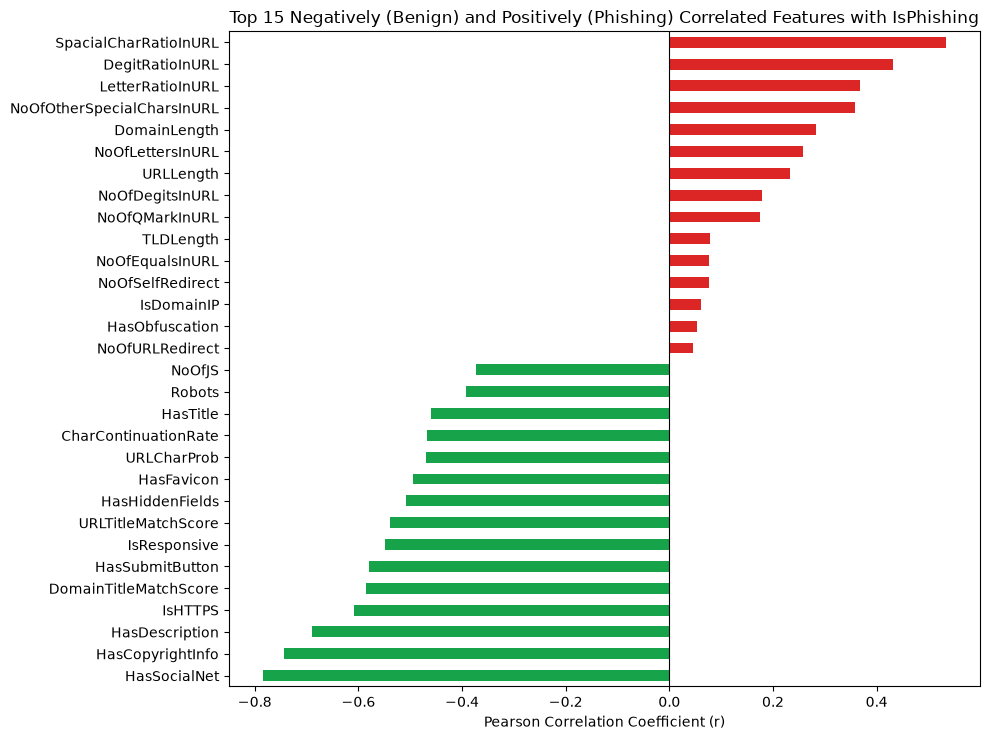

In [7]:
# EXERCISE 3: Constructing X, y and Analyzing Target Correlations
cols_to_drop = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label', 'IsPhishing', 'URLSimilarityIndex']

### START CODE HERE ### (≈ 3 lines of code)
X = df.drop(columns=cols_to_drop)
y = df['IsPhishing']
correlations = X.corrwith(y).sort_values()
### END CODE HERE ###

print("Shape of X:", X.shape, "| Shape of y:", y.shape)

# Plot Top 15 Negatively and Top 15 Positively Correlated Features
top_corr = pd.concat([correlations.head(15), correlations.tail(15)])
plt.figure(figsize=(10, 7.5))
colors = ['#16a34a' if c < 0 else '#dc2626' for c in top_corr.values]
top_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Top 15 Negatively (Benign) and Positively (Phishing) Correlated Features with IsPhishing")
plt.xlabel("Pearson Correlation Coefficient (r)")
plt.tight_layout()
plt.show()

---
### 💡 Part 1 Reflection Questions

1. **Looking at your plot for `IsHTTPS`, what percentage of phishing sites currently use an HTTPS certificate? Why is a static rule *"If HTTPS then Legitimate"* dangerous?**
   * **Answer:** _______

2. **Why do phishing websites typically have very few internal links (`NoOfSelfRef`) but very frequently contain a password field (`HasPasswordField`)?**
   * **Answer:** _______

3. **What would happen in production if we left the `FILENAME`, `URL`, or `Domain` column in our training matrix?**
   * **Answer:** _______

---
## 3 - Part 2: Zero-Data Leakage Preprocessing & Standardization

### 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)

We apply the **SecMLOps Golden Rule**: split the dataset into training (75%) and test (25%) subsets *before* computing Z-score normalization parameters ($\mu_{\text{train}}, \sigma_{\text{train}}$).

### Exercise 4

In [8]:
# EXERCISE 4: Stratified Split and Leakage-Free Standardization

### START CODE HERE ### (≈ 4 lines of code)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
### END CODE HERE ###

# Retain column names and indices for weight and SHAP interpretability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("Train shape:", X_train_scaled.shape, "| Test shape:", X_test_scaled.shape)
print("Mean of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].mean(), 4))
print("Std of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].std(), 4))

Train shape: (176846, 49) | Test shape: (58949, 49)
Mean of X_train_scaled (URLLength): -0.0
Std of X_train_scaled (URLLength): 1.0


---
### 💡 Part 2 Reflection Questions

1. **Compare the scale of `LineOfCode` (values up to 10,000+) and `IsHTTPS` (0 or 1) before standardization. Why would L1/L2 regularization be skewed without `StandardScaler`?**
   * **Answer:**

2. **Precisely explain why calling `scaler.fit_transform(X)` before `train_test_split` constitutes Preprocessing Data Leakage.**
   * **Answer:**

---
## 4 - Part 3: Parameterized Logistic Regression & Interpretability

### 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)

We train and evaluate the five specified Logistic Regression configurations on `X_train_scaled` and `X_test_scaled`:
* **M1: Unregularized (`penalty=None`)**
* **M2: Strong L2 Ridge (`penalty='l2', C=0.001`)**
* **M3: Standard L2 Ridge (`penalty='l2', C=1.0`)**
* **M4: Sparse L1 Lasso (`penalty='l1', C=0.01`)**
* **M5: SOC Weighted (`penalty='l2', C=1.0, class_weight='balanced'`)**

### Exercise 5

In [11]:
# EXERCISE 5: Training and Comparing 5 Logistic Regression Configurations
configurations = {
    "M1: Unregularized (None)": LogisticRegression(penalty=None, solver='lbfgs', max_iter=500, random_state=SEED),
    "M2: Strong L2 Ridge (C=0.001)": LogisticRegression(penalty='l2', C=0.001, solver='lbfgs', max_iter=500, random_state=SEED),
    "M3: Standard L2 Ridge (C=1.0)": LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=500, random_state=SEED),
    "M4: Sparse L1 Lasso (C=0.01)": LogisticRegression(penalty='l1', C=0.01, solver='liblinear', max_iter=500, random_state=SEED),
    "M5: SOC Weighted (balanced)": LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', solver='lbfgs', max_iter=500, random_state=SEED),
}

results = []
for name, model in configurations.items():
    ### START CODE HERE ### (≈ 5 lines of code)
    model.fit(X_train_scaled, y_train)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = (y_prob >= 0.50).astype(int)
    w = model.coef_[0]
    n_zero_weights = int(np.sum(np.abs(w) < 1e-4))
    ### END CODE HERE ###

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results.append({
        "Model": name,
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall (TPR)": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4),
        "False Alarms (FP)": int(fp),
        "Missed Phish (FN)": int(fn),
        "Zeroed Weights (Sparsity)": f"{n_zero_weights} / {len(w)}"
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Precision,Recall (TPR),F1-Score,PR-AUC,False Alarms (FP),Missed Phish (FN),Zeroed Weights (Sparsity)
0,M1: Unregularized (None),0.9996,0.9990,0.9993,1.0,11,25,0 / 49
1,M2: Strong L2 Ridge (C=0.001),0.9985,0.9958,0.9971,1.0,39,105,0 / 49
2,M3: Standard L2 Ridge (C=1.0),0.9996,0.9989,0.9992,1.0,10,28,0 / 49
3,M4: Sparse L1 Lasso (C=0.01),0.9993,0.9971,0.9982,1.0,18,72,24 / 49
4,M5: SOC Weighted (balanced),0.9995,0.9990,0.9992,1.0,13,25,0 / 49


---
### 4.2 L1 Regularization Path & Feature Selection (Exercise 6)

We vary `C` across `[0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]` with `penalty='l1'` (`solver='liblinear'`) and plot the number of retained features ($|w_j| \ge 10^{-4}$) as a function of `C` on a logarithmic scale.

### Exercise 6

C = 0.002 -> active features: 10
C = 0.01 -> active features: 16
C = 0.05 -> active features: 17
C = 0.1 -> active features: 20
C = 0.5 -> active features: 27
C = 1.0 -> active features: 30
C = 5.0 -> active features: 32


,C,Active_Features,Zeroed_Features
0,0.002,10,39
1,0.010,16,33
2,0.050,17,32
3,0.100,20,29
4,0.500,27,22
5,1.000,30,19
6,5.000,32,17


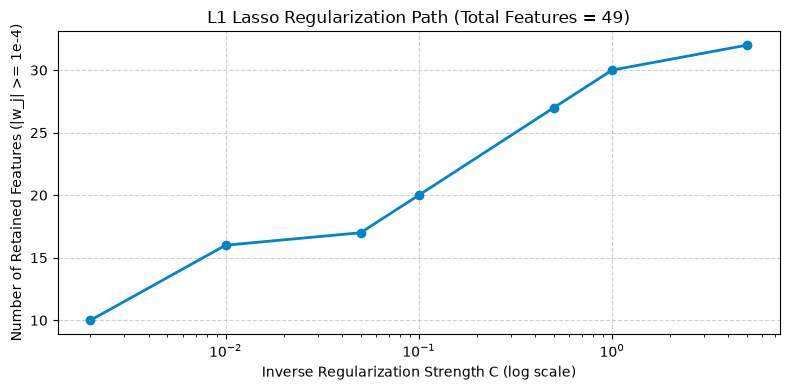

In [10]:
# EXERCISE 6: L1 Regularization Path (Number of Active Features vs. C)
import warnings
warnings.filterwarnings("ignore") 

C_values = [0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
active_features_count = []

X_tr_s = X_train_scaled.sample(n=10000, random_state=SEED)
y_tr_s = y_train.loc[X_tr_s.index]

for c_val in C_values:
    ### START CODE HERE ### (≈ 3 lines of code)
    m_l1 = LogisticRegression(penalty='l1', C=c_val, solver='liblinear', max_iter=50, random_state=SEED)
    m_l1_fit =  m_l1.fit(X_tr_s, y_tr_s)
    n_active = int(np.sum(np.abs(m_l1_fit.coef_[0]) >= 1e-4))
    ### END CODE HERE ###
    print("C =", c_val, "-> active features:", n_active)
    active_features_count.append(n_active)

path_df = pd.DataFrame({"C": C_values, "Active_Features": active_features_count, "Zeroed_Features": [X.shape[1] - k for k in active_features_count]})
display(path_df)

plt.figure(figsize=(8, 4))
plt.plot(C_values, active_features_count, marker='o', linewidth=2, color='#0284c7')
plt.xscale('log')
plt.xlabel("Inverse Regularization Strength C (log scale)")
plt.ylabel("Number of Retained Features (|w_j| >= 1e-4)")
plt.title(f"L1 Lasso Regularization Path (Total Features = {X.shape[1]})")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---
### 4.3 Interpreting Coefficients ($w_j$) and Odds Ratios ($e^{w_j}$) (Exercise 7)

We extract the learned log-odds weights $w_j$ from `M3: Standard L2 Ridge (C=1.0)`, compute the Odds Ratio $e^{w_j}$, compare against `M4: Sparse L1 Lasso (C=0.01)`, and display the **Top 8 Phishing** ($w_j > 0$) and **Top 8 Benign** ($w_j < 0$) features.

### Exercise 7

In [ ]:
# EXERCISE 7: Inspecting Log-Odds (w_j) and Odds Ratios (exp(w_j))
model_l2 = configurations["M3: Standard L2 Ridge (C=1.0)"]
model_l1 = configurations["M4: Sparse L1 Lasso (C=0.01)"]

### START CODE HERE ### (≈ 4 lines of code)
weights_df =  pd.DataFrame({
    "Feature": X.columns,
    "Weight (w_j)": model_l2.coef_[0],
    "Odds Ratio exp(w_j)": np.exp(model_l2.coef_[0]),
    "L1_Sparse_Weight": model_l1.coef_[0]
}).sort_values("Weight (w_j)", ascending=False)
### END CODE HERE ###

print("🔴 TOP 8 FEATURES PUSHING TOWARD PHISHING (w_j > 0):")
display(weights_df.head(8).round(4))

print("\n🟢 TOP 8 FEATURES PUSHING TOWARD BENIGN (w_j < 0):")
display(weights_df.tail(8).round(4))

---
### 💡 Part 3 Reflection Questions —

1. **How many variables did `M4: Sparse L1 Lasso (C=0.01)` eliminate (weights set to zero)? Did the F1-Score drop significantly? What is the advantage for a real-time firewall?**
   * **Answer:**

2. **What is the impact of `class_weight='balanced'` (M5) on False Positives and False Negatives compared to M3?**
   * **Answer:**

3. **How do you interpret a positive weight $w_j > 0$ versus a negative weight $w_j < 0$ in the formula $\sigma(\mathbf{w}^\top\mathbf{x} + b)$?**
   * **Answer:**

---
## 5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis

### 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)

We initialize `shap.LinearExplainer` on `model_l2` (`M3`) using `X_train_scaled` as the background reference distribution, compute exact Shapley values on the first `1,000` test URLs, and plot the global Bar and Beeswarm charts (`max_display=15`).

### Exercise 8

In [ ]:
# EXERCISE 8: Computing SHAP Values and Global Importance Plots (1,000 Test URLs)
X_test_sample = X_test_scaled.iloc[:1000]

### START CODE HERE ### (≈ 2 lines of code)
explainer = shap.LinearExplainer(model_l2, X_train_scaled)
shap_values = explainer(X_test_sample)
### END CODE HERE ###

# 1. Global Mean Absolute SHAP Importance (Bar Plot)
shap.plots.bar(shap_values, max_display=15)

# 2. Global Directional Impact (Beeswarm Plot)
shap.plots.beeswarm(shap_values, max_display=15)

---
### 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)

We locate the first **True Positive (TP)**, **True Negative (TN)**, and **False Positive (FP — False Alarm)** in our 1,000-URL test sample and inspect their local SHAP Waterfall plots (`max_display=10`), passing unscaled `X_test` values in `data=` so SOC analysts can read actual URL metrics.

### Exercise 9

In [ ]:
# EXERCISE 9: Local SOC Triage of TP, TN, and FP Cases with SHAP Waterfall
y_test_sample = y_test.iloc[:1000].values
y_prob_sample = model_l2.predict_proba(X_test_sample)[:, 1]
y_pred_sample = (y_prob_sample >= 0.50).astype(int)

### START CODE HERE ### (≈ 3 lines of code)
tp_idx = int(np.where((y_test_sample == 1) & (y_pred_sample == 1))[0][0])
tn_idx = int(np.where((y_test_sample == 0) & (y_pred_sample == 0))[0][0])
fp_candidates = np.where((y_test_sample == 0) & (y_pred_sample == 1))[0]
### END CODE HERE ###

fp_idx = int(fp_candidates[0]) if len(fp_candidates) > 0 else int(np.argmax(y_prob_sample * (y_test_sample == 0)))

def plot_soc_waterfall(idx, case_title):
    print(f"=== {case_title} (Sample Index={idx}) | True Label={y_test_sample[idx]} | P(Phishing)={y_prob_sample[idx]*100:.2f}% ===")
    local_exp = shap.Explanation(
        values=shap_values.values[idx],
        base_values=float(np.ravel(shap_values.base_values)[idx]),
        data=X_test.iloc[idx].values, # Unscaled values for human analyst readability
        feature_names=X.columns
    )
    shap.plots.waterfall(local_exp, max_display=10)

plot_soc_waterfall(tp_idx, "CASE 1: TRUE POSITIVE (Confirmed Phishing Attack Caught)")
plot_soc_waterfall(tn_idx, "CASE 2: TRUE NEGATIVE (Legitimate Traffic Correctly Cleared)")
plot_soc_waterfall(fp_idx, "CASE 3: FALSE POSITIVE (Legitimate Site Wrongly Flagged — False Alarm)")

---
### 5.3 Operational Decision Threshold Tuning ($\tau \in \{0.20, 0.50, 0.85\}$) (Exercise 10)

We evaluate `model_l2` (`M3`) on the full test set across three operational decision thresholds:
* **$\tau = 0.20$ (Threat Hunting Mode):** Maximizes Recall to catch stealthy phishing campaigns.
* **$\tau = 0.50$ (Default Mode):** Balanced threshold.
* **$\tau = 0.85$ (Automated Firewall Blocking Mode):** Maximizes Precision and minimizes False Positives to prevent blocking legitimate business traffic.

### Exercise 10

In [ ]:
# EXERCISE 10: Comparing Operational Decision Thresholds (0.20, 0.50, 0.85)
y_prob_full = model_l2.predict_proba(X_test_scaled)[:, 1]
thresholds = [0.20, 0.50, 0.85]
threshold_records = []

for tau in thresholds:
    ### START CODE HERE ### (≈ 2 lines of code)
    y_pred_tau = (y_prob_full >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tau).ravel()
    ### END CODE HERE ###

    threshold_records.append({
        "Threshold (tau)": tau,
        "SOC Operational Mode": "Threat Hunting" if tau == 0.20 else ("Default" if tau == 0.50 else "Automated Blocking"),
        "Precision": round(precision_score(y_test, y_pred_tau), 4),
        "Recall (TPR)": round(recall_score(y_test, y_pred_tau), 4),
        "F1-Score": round(f1_score(y_test, y_pred_tau), 4),
        "True Positives (TP)": int(tp),
        "True Negatives (TN)": int(tn),
        "False Positives (FP)": int(fp),
        "False Negatives (FN)": int(fn)
    })

threshold_df = pd.DataFrame(threshold_records)
display(threshold_df)

---
### 💡 Part 4 Reflection Questions —

1. **What is the mathematical difference between inspecting a global weight $w_j$ and looking at a local SHAP value $\phi_j(x)$ for a specific URL?**
   * **Answer:**

2. **On your False Positive (FP) Waterfall plot, which 2 or 3 features misled the model and caused this false alarm?**
   * **Answer:**

3. **Why would a SOC deploy $\tau = 0.85$ for automated DNS/firewall blocking while routing URLs with $0.20 \le P(\text{Phishing}) < 0.85$ to a human analyst queue?**
   * **Answer:**

---
## 6 - Conclusion & SOC Engineering Synthesis (Deliverable Solution)

> ### 🛡️ SOC Engineering Synthesis Report
> 1. **Hyperparameter & Sparsity Trade-Off:**

> 2. **Global Interpretability (Odds Ratios & SHAP):**

> 3. **SOC Alert Triage & Dual-Threshold Policy:**
  * *False Positive Triage Note (3 sentences):*

  * *Recommended Threshold Policy:*